# 02 · Feature Engineering & Model Development

This notebook walks through `heart.train`, the same code that `make train` and the CI `train` job run. The notebook explains it and shows the intermediate results; it doesn't reimplement anything.

**Pipeline:** stratified 80/20 split → grid search with stratified 5-fold CV for each model → pick a model with the one-standard-error rule → tune the decision threshold for recall → quality gate → one evaluation on the held-out test set.

In [1]:
import pandas as pd
from IPython.display import Image, display

from heart import train
from heart.config import CV_FOLDS, FEATURES, TARGET_RECALL
from heart.data import load_processed
from heart.features import build_preprocessor
from heart.models import candidates

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)

## 1. Feature engineering

Every decision below comes from the EDA notebook. All the preprocessing lives in one `ColumnTransformer`, which becomes the first step of every model `Pipeline`:

| Group | Columns | Steps | Why |
|---|---|---|---|
| Numeric | `age, trestbps, chol, thalach, oldpeak` | median impute → standard scale | Very different scales; median is robust to the skewed `oldpeak` and `chol` |
| Categorical | `cp, restecg, slope, ca, thal` | most-frequent impute → one-hot | Codes are labels, not quantities (`cp=4` isn't "twice" `cp=2`) |
| Binary | `sex, fbs, exang` | most-frequent impute | Already 0/1 |

The one-hot categories are **fixed from the UCI codebook**, not learned from data. `restecg=1` has only 4 patients, so some CV folds won't contain it. Fixed categories mean the feature matrix always has the same 25 columns.

In [2]:
df = load_processed()
pre = build_preprocessor().fit(df[FEATURES])
names = pre.get_feature_names_out()
print(f"{len(FEATURES)} raw columns  ->  {len(names)} model features")
pd.DataFrame(pre.transform(df[FEATURES].head(3)), columns=names).round(2)

13 raw columns  ->  25 model features


,age,trestbps,chol,thalach,oldpeak,cp_1,cp_2,cp_3,cp_4,restecg_0,...,ca_0,ca_1,ca_2,ca_3,thal_3,thal_6,thal_7,sex,fbs,exang
0,0.95,0.76,-0.26,0.02,1.09,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0
1,1.39,1.61,0.76,-1.82,0.40,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0
2,1.39,-0.67,-0.34,-0.90,1.35,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0


**Why the preprocessing goes inside the pipeline:** inside cross-validation, the scaler's mean/std and the imputer's medians are re-learned **on each training fold only**. Fitting them on all 303 rows first would leak test-fold information into training and inflate the scores. Saving the whole pipeline also means the API gets the exact same transformation for free.

## 2. Train / test split and cross-validation

- **80/20 stratified split:** 242 training rows, 61 test rows, the same class ratio in both. The test set is **used once**, at the very end.
- **Stratified 5-fold CV on the training set** is used for *every* decision (hyperparameters, model choice, threshold). With only 242 rows, a single validation split would be noisy, so averaging 5 folds and reporting the std shows how stable each score is.

In [3]:
result = train.run()
print(f"train: {len(result.X_train)} rows (disease rate {result.y_train.mean():.1%})")
print(f"test:  {len(result.X_test)} rows (disease rate {result.y_test.mean():.1%})")

train: 242 rows (disease rate 45.9%)
test:  61 rows (disease rate 45.9%)


## 3. Candidate models and hyperparameter search

| Model | Why it's a candidate | Grid |
|---|---|---|
| **Dummy** (stratified) | A floor every real model must clearly beat | — |
| **Logistic Regression** | Simple, interpretable coefficients, strong on small tabular data | `C` (regularization strength) × L1/L2 |
| **Random Forest** | Captures non-linearities and interactions; robust | depth, min leaf size, features per split |
| **Gradient Boosting** | Usually the strongest tabular learner | trees, learning rate, depth, subsample |

`GridSearchCV` tries every combination with 5-fold CV, ranks them by **ROC-AUC** (threshold-independent, so it measures ranking quality before we pick a threshold), and records accuracy, precision, recall and F1 too.

In [4]:
for c in candidates():
    n = 1
    for v in c.grid.values():
        n *= len(v)
    print(f"{c.name:20s} {n:3d} combinations x {CV_FOLDS} folds = {n * CV_FOLDS:3d} fits")

dummy                  1 combinations x 5 folds =   5 fits
logistic_regression   14 combinations x 5 folds =  70 fits
random_forest         18 combinations x 5 folds =  90 fits
gradient_boosting     16 combinations x 5 folds =  80 fits


### How tuning moved Logistic Regression
Smaller `C` means stronger regularization. Very small `C` underfits; past a point, larger `C` adds nothing.

In [5]:
lr = next(t for t in result.tuned if t.name == "logistic_regression")
lr.grid_results.pivot(index="C", columns="l1_ratio", values="mean_test_roc_auc").rename(
    columns={0.0: "L2 (l1_ratio=0)", 1.0: "L1 (l1_ratio=1)"}
)

l1_ratio,L2 (l1_ratio=0),L1 (l1_ratio=1)
C,,
0.01,0.885,0.500
0.03,0.893,0.771
0.10,0.901,0.884
0.30,0.904,0.905
1.00,0.905,0.903
3.00,0.903,0.903
10.00,0.901,0.901


### Top Random Forest and Gradient Boosting configurations

In [6]:
score_cols = ["mean_test_roc_auc", "std_test_roc_auc", "mean_test_recall"]
for name in ("random_forest", "gradient_boosting"):
    grid = next(t for t in result.tuned if t.name == name).grid_results
    param_cols = [c for c in grid.columns if not c.startswith(("mean_", "std_"))]
    print(name)
    top = grid.sort_values("mean_test_roc_auc", ascending=False).head(5)
    display(top[param_cols + score_cols])

random_forest


,max_depth,max_features,min_samples_leaf,mean_test_roc_auc,std_test_roc_auc,mean_test_recall
8,4,sqrt,5,0.901,0.026,0.792
1,None,sqrt,3,0.901,0.022,0.765
6,4,sqrt,1,0.901,0.022,0.783
2,None,sqrt,5,0.900,0.026,0.783
14,8,sqrt,5,0.900,0.026,0.783


gradient_boosting


,learning_rate,max_depth,n_estimators,subsample,mean_test_roc_auc,std_test_roc_auc,mean_test_recall
0,0.03,2,100,0.8,0.884,0.030,0.756
1,0.03,2,100,1.0,0.879,0.031,0.783
4,0.03,3,100,0.8,0.877,0.029,0.765
5,0.03,3,100,1.0,0.876,0.026,0.738
2,0.03,2,200,0.8,0.874,0.028,0.765


## 4. Comparing the tuned models (cross-validated, training set)

In [7]:
train.comparison_table(result)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
dummy,0.525 ± 0.076,0.478 ± 0.105,0.396 ± 0.084,0.433 ± 0.093,0.515 ± 0.077
logistic_regression,0.831 ± 0.016,0.867 ± 0.060,0.756 ± 0.086,0.801 ± 0.031,0.905 ± 0.014
random_forest,0.834 ± 0.031,0.846 ± 0.064,0.792 ± 0.080,0.813 ± 0.037,0.901 ± 0.026
gradient_boosting,0.818 ± 0.036,0.846 ± 0.082,0.756 ± 0.070,0.792 ± 0.035,0.884 ± 0.030


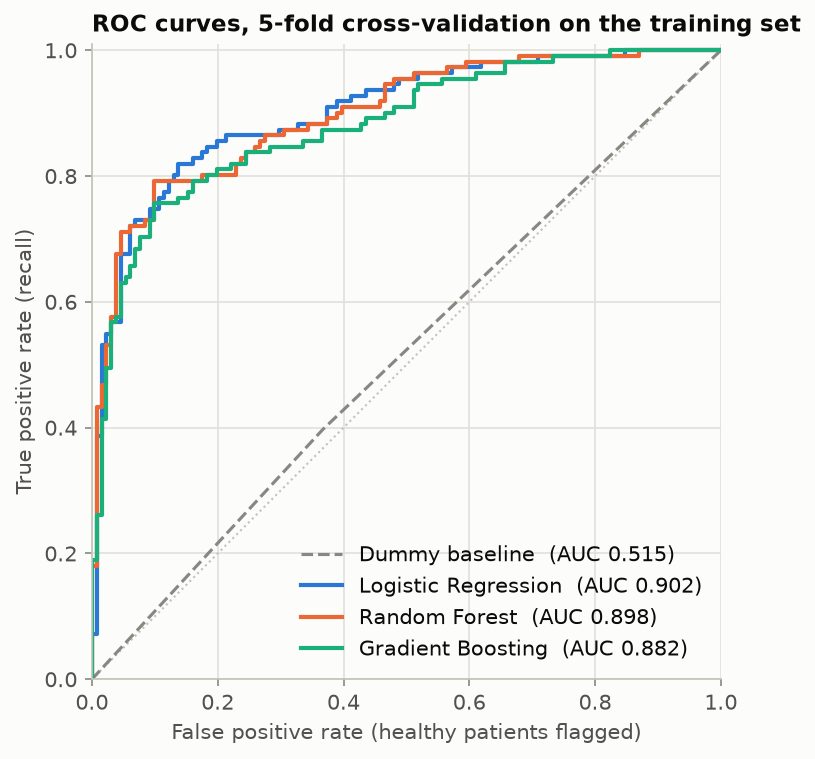

In [8]:
figures = train.save_figures(result)
display(Image(figures[0]))

**Model selection: the one-standard-error rule.** LR (0.905), RF (0.901) and GB (0.884) are close. The gaps are smaller than the fold-to-fold noise (std 0.014–0.030), so "best mean score" isn't a reliable signal on 242 rows. The rule: take the best mean ROC-AUC, subtract one standard error (std/√5), and choose the **simplest** model that clears that bar. Candidates are listed simplest first.

Logistic Regression wins both on score and on simplicity. It also has the lowest variance across folds (±0.014), it's fast, and its coefficients are directly interpretable. That last point matters for a clinical use case, and it lets the API explain its predictions later.

In [9]:
print("Selected:", result.selected.name, result.selected.params)

Selected: logistic_regression {'C': 0.3, 'l1_ratio': 1.0}


## 5. Tuning the decision threshold for recall

`predict()` defaults to "disease if probability ≥ 0.5". But the two kinds of error don't cost the same in screening:
- **False negative** (missed disease): the patient goes home untreated. Very costly.
- **False positive** (false alarm): the patient gets a follow-up test. Comparatively cheap.

So we **lower the threshold** until cross-validated recall reaches the target in `config.TARGET_RECALL` (90%), and pick the highest threshold that does, to keep precision as high as possible. This uses out-of-fold probabilities from the training set; the test set is still unseen.

target recall 90%  ->  chosen threshold 0.304


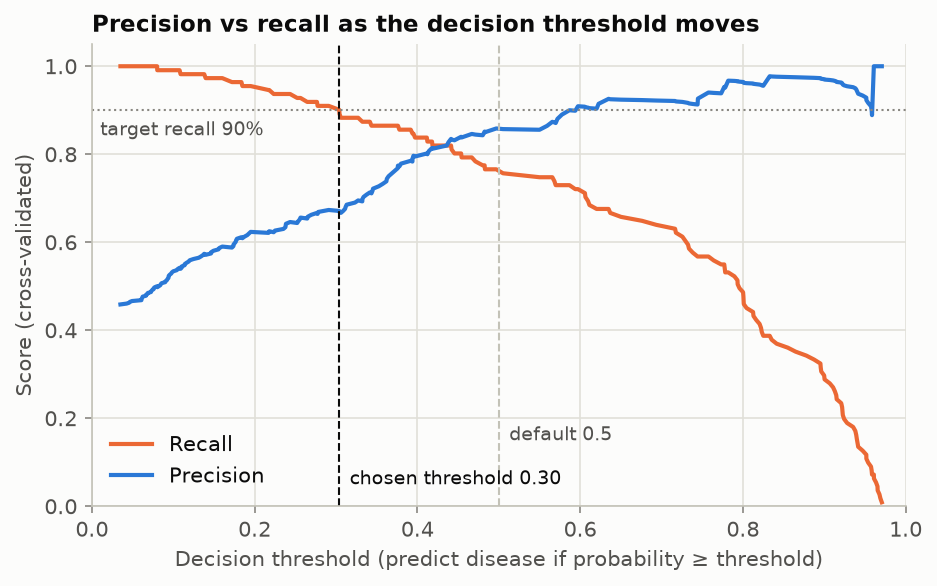

In [10]:
print(f"target recall {TARGET_RECALL:.0%}  ->  chosen threshold {result.threshold:.3f}")
display(Image(figures[1]))

The shipped model wraps the pipeline in a `FixedThresholdClassifier`. So `model.predict()` applies the tuned threshold, while `model.predict_proba()` still returns raw probabilities for the API's confidence score.

## 6. Quality gate
Training exits with an error if the selected model's CV ROC-AUC is under the minimum, or doesn't beat the dummy. In CI, that turns the run red and stops a bad model from ever being packaged.

In [11]:
print(train.quality_gate(result.selected, result.tuned) or "passed")

passed


## 7. Final evaluation on the held-out test set (used once)

In [12]:
pd.DataFrame(
    {
        f"tuned threshold ({result.threshold:.2f})": result.test_metrics,
        "default threshold (0.50)": result.test_metrics_default_threshold,
    }
).T

,accuracy,precision,recall,f1,roc_auc
tuned threshold (0.30),0.820,0.730,0.964,0.831,0.969
default threshold (0.50),0.885,0.839,0.929,0.881,0.969


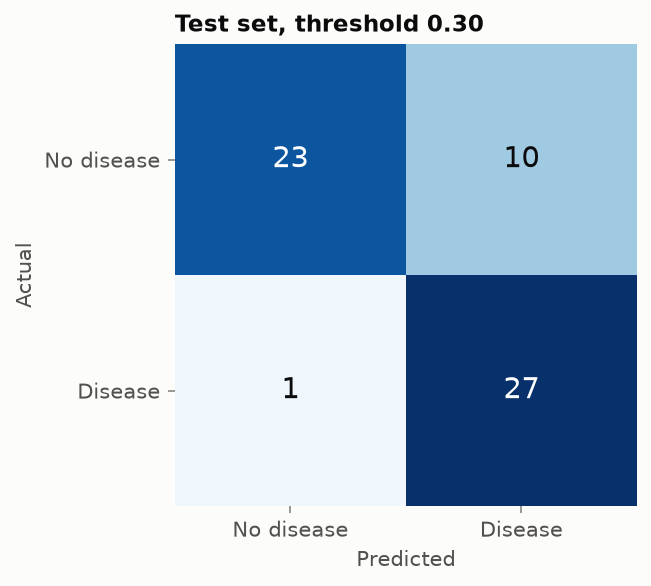

In [13]:
display(Image(figures[2]))

**Reading the results**
- Test ROC-AUC is about 0.97. That's higher than CV (about 0.90), which is common luck with only 61 test rows. The **CV estimate (0.905 ± 0.014) is the more trustworthy number** to report.
- At the tuned threshold, the model misses **1 of 28** disease cases (recall 0.96) at the cost of 10 false alarms out of 33 healthy patients. That's the trade-off we chose deliberately.
- At 0.5 the test accuracy is higher (0.885 vs 0.820). Accuracy is the wrong metric here, because it treats a missed diagnosis and a false alarm as equally bad.

## 8. What the model learned

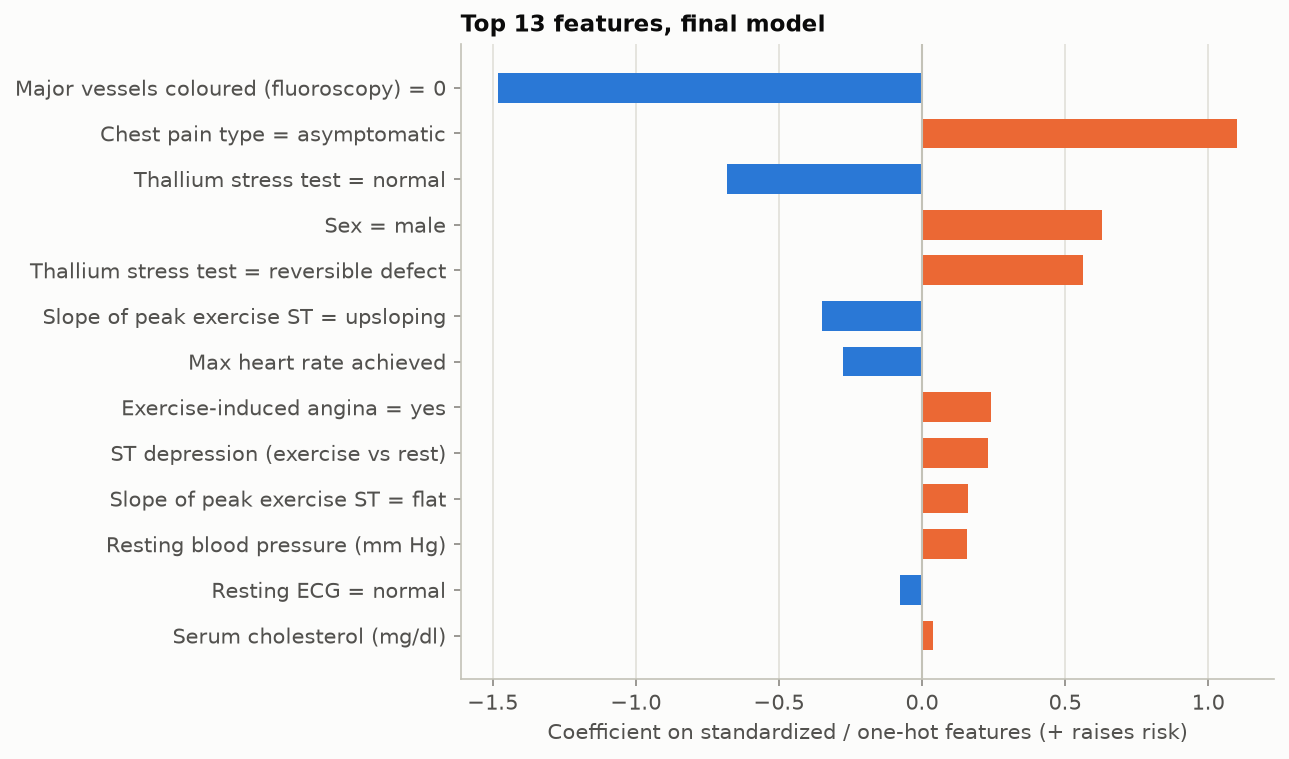

In [14]:
display(Image(figures[3]))

- These are coefficients on standardized/one-hot features. Positive (orange) raises predicted risk; negative (blue) lowers it.
- The strongest signals match the EDA: **0 vessels coloured** (protective), **asymptomatic chest pain**, **thallium test result**, **sex = male**, and **max heart rate** (higher is protective).
- L1 regularization set 11 of the 25 weights to exactly zero. That's automatic feature selection:
  - **Fasting blood sugar** is dropped, which matches the EDA (45% vs 49% disease rate, so almost no signal).
  - **Age** is dropped too, even though it clearly shifts with disease. Its information overlaps with `ca` (r = 0.36) and max heart rate (r = −0.39), and L1 keeps one of a group of correlated features rather than spreading weight across all of them. So "zero weight" means "redundant given the others", **not** "irrelevant".
- `Sex = male` raising risk reflects a real dataset imbalance (68% male). It goes in the model card as a limitation.

## Summary

| Decision | Choice | Evidence |
|---|---|---|
| Preprocessing | Impute + scale + one-hot inside the pipeline | Avoids leakage; same transform at serve time |
| Model | L1 Logistic Regression, C=0.3 | Best CV ROC-AUC (0.905 ± 0.014), simplest, interpretable |
| Threshold | about 0.30 instead of 0.5 | ≥90% CV recall; a missed diagnosis costs more than a false alarm |
| Reported metric | CV ROC-AUC, plus test-set recall/precision | CV is more stable than a 61-row test set |